# Opening Charts

Los Angeles is used as an example.

In [14]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import transform
from rasterio.transform import rowcol
from rasterio.windows import Window

In [15]:
# Open the chart file. This reads only the file information, not the pixels.
src = rasterio.open("../data/raw/Los_Angeles/Los Angeles SEC.tif")

# Image size, number of color bands, map projection, and pixel-to-map transform.
print("Size (width x height):", src.width, "x", src.height)
print("Bands:", src.count)
print("CRS:", src.crs)
print("Transform:", src.transform)

Size (width x height): 16645 x 12349
Bands: 1
CRS: PROJCS["Lambert Conformal Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",34.1666666666667],PARAMETER["central_meridian",-118.466666666667],PARAMETER["standard_parallel_1",38.6666666666667],PARAMETER["standard_parallel_2",33.3333333333333],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Transform: | 42.34, 0.00,-351020.46|
| 0.00,-42.34, 277738.99|
| 0.00, 0.00, 1.00|


In [16]:
# low_memory=False makes pandas find one data type for each column.
apt = pd.read_csv("../data/raw/29_Oct_2026_APT_CSV/APT_BASE.csv", low_memory=False)
nav = pd.read_csv("../data/raw/29_Oct_2026_NAV_CSV/NAV_BASE.csv", low_memory=False)

In [17]:
apt.head()

,EFF_DATE,SITE_NO,SITE_TYPE_CODE,STATE_CODE,ARPT_ID,CITY,COUNTRY_CODE,REGION_CODE,ADO_CODE,STATE_NAME,...,CONTR_FUEL_AVBL,TRNS_STRG_BUOY_FLAG,TRNS_STRG_HGR_FLAG,TRNS_STRG_TIE_FLAG,OTHER_SERVICES,WIND_INDCR_FLAG,ICAO_ID,MIN_OP_NETWORK,USER_FEE_FLAG,CTA
0,2026/10/29,103.00,A,AL,0J0,ABBEVILLE,US,ASO,JAN,ALABAMA,...,NaN,NaN,NaN,Y,NaN,Y-L,NaN,N,NaN,NaN
1,2026/10/29,106.00,A,AL,2A8,ADDISON,US,ASO,JAN,ALABAMA,...,NaN,NaN,NaN,N,NaN,Y,NaN,N,NaN,NaN
2,2026/10/29,108.00,A,AL,AL03,AKRON,US,ASO,JAN,ALABAMA,...,NaN,NaN,NaN,NaN,NaN,Y,NaN,N,NaN,NaN
3,2026/10/29,110.00,A,AL,EET,ALABASTER,US,ASO,JAN,ALABAMA,...,NaN,NaN,NaN,Y,"INSTR,RNTL,SALES",Y-L,KEET,N,NaN,NaN
4,2026/10/29,110.01,H,AL,AL39,ALABASTER,US,ASO,JAN,ALABAMA,...,NaN,NaN,NaN,NaN,NaN,Y,NaN,N,NaN,NaN


In [18]:
apt['SITE_TYPE_CODE'].unique()

<StringArray>
['A', 'H', 'C', 'G', 'U', 'B']
Length: 6, dtype: str

In [19]:
# Keep only airports. Remove heliports, seaplane bases, and other types.
apt = apt[apt["SITE_TYPE_CODE"] == "A"]

print("Airports:", len(apt))
print("Navaids:", len(nav))

Airports: 13005
Navaids: 1608


In [21]:
def to_pixels(df):
    # Convert latitude and longitude (EPSG:4326) to the chart projection.
    xs, ys = transform("EPSG:4326", src.crs, df["LONG_DECIMAL"].tolist(), df["LAT_DECIMAL"].tolist())

    # Convert the projection coordinates to pixel row and column.
    rows, cols = rowcol(src.transform, xs, ys)

    df = df.copy()
    df["px_row"] = rows
    df["px_col"] = cols

    # Keep only the points inside the chart image.
    inside = df["px_row"].between(0, src.height - 1) & df["px_col"].between(0, src.width - 1)
    return df[inside]

apt_la = to_pixels(apt)
nav_la = to_pixels(nav)

print("Airports on chart:", len(apt_la))
print("Navaids on chart:", len(nav_la))

Airports on chart: 227
Navaids on chart: 70


In [22]:
def to_pixels(df):
    # Convert latitude and longitude (EPSG:4326) to the chart projection.
    xs, ys = transform("EPSG:4326", src.crs, df["LONG_DECIMAL"].tolist(), df["LAT_DECIMAL"].tolist())

    # Convert the projection coordinates to pixel row and column.
    rows, cols = rowcol(src.transform, xs, ys)

    df = df.copy()
    df["px_row"] = rows
    df["px_col"] = cols

    # Keep only the points inside the chart image.
    inside = df["px_row"].between(0, src.height - 1) & df["px_col"].between(0, src.width - 1)
    return df[inside]

apt_la = to_pixels(apt)
nav_la = to_pixels(nav)

print("Airports on chart:", len(apt_la))
print("Navaids on chart:", len(nav_la))

Airports on chart: 227
Navaids on chart: 70


In [23]:
# Find the pixel position of LAX airport.
lax = apt_la[apt_la["ARPT_ID"] == "LAX"].iloc[0]
r, c = int(lax["px_row"]), int(lax["px_col"])

# Make a 2000 x 2000 pixel area with LAX at the center.
half = 1000
r0, r1 = max(r - half, 0), min(r + half, src.height)
c0, c1 = max(c - half, 0), min(c + half, src.width)

In [24]:
# Read only the selected area, not the full chart.
window = Window(c0, r0, c1 - c0, r1 - r0)
band = src.read(1, window=window)

# The chart has 1 band with a color table. Each pixel value is an index into that table.
# Make a lookup table that converts each index to an RGB color.
lut = np.zeros((256, 3), dtype=np.uint8)
for index, color in src.colormap(1).items():
    lut[index] = color[:3]

crop = lut[band]

/var/folders/hv/ssw7w9251n33ldwz20jqx8qw0000gn/T/ipykernel_44805/178158574.py:3: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  band = src.read(1, window=window)


In [29]:
# Read the table again, with no filter.
apt_all = pd.read_csv("../data/raw/29_Oct_2026_APT_CSV/APT_BASE.csv", low_memory=False)

# LAX and VNY stayed. SMO, HHR, TOA, LGB, and BUR were removed.
known = ["LAX", "VNY", "SMO", "HHR", "TOA", "LGB", "BUR"]
apt_all[apt_all["ARPT_ID"].isin(known)][["ARPT_ID", "ARPT_NAME", "SITE_TYPE_CODE", "LAT_DECIMAL", "LONG_DECIMAL"]]

,ARPT_ID,ARPT_NAME,SITE_TYPE_CODE,LAT_DECIMAL,LONG_DECIMAL
1072,BUR,HOLLYWOOD BURBANK,A,34.200694,-118.358667
1279,HHR,JACK NORTHROP FLD/HAWTHORNE MUNI,A,33.922861,-118.335083
1381,LGB,LONG BEACH (DAUGHERTY FLD),A,33.817930,-118.151891
1432,LAX,LOS ANGELES INTL,A,33.942496,-118.408049
1713,SMO,SANTA MONICA MUNI,A,34.015822,-118.451306
1778,TOA,ZAMPERINI FLD,A,33.803383,-118.339608
1810,VNY,VAN NUYS,A,34.209806,-118.489972


     ARPT_ID  px_row  px_col
1072     BUR  6471.0  8526.0
1101    64CL  7376.0  8707.0
1141     CPM  7284.0  8778.0
1194     EMT  6769.0  9232.0
1240     FUL  7329.0  9355.0
1279     HHR  7198.0  8578.0
1381     LGB  7472.0  8979.0
1388     SLI  7544.0  9199.0
1432     LAX  7147.0  8419.0
1433     WHP  6317.0  8407.0
1713     SMO  6955.0  8324.0
1778     TOA  7511.0  8569.0
1810     VNY  6447.0  8240.0


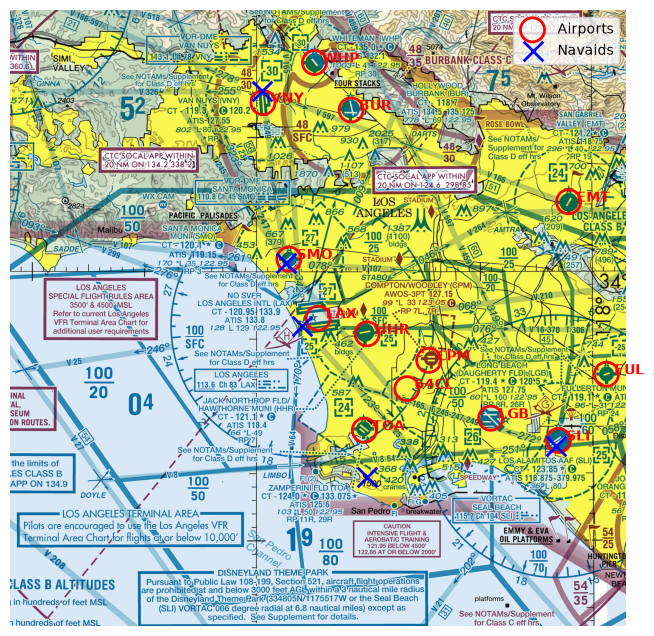

In [31]:
# Keep only the points inside the selected area.
a = apt_la[apt_la["px_row"].between(r0, r1 - 1) & apt_la["px_col"].between(c0, c1 - 1)]
n = nav_la[nav_la["px_row"].between(r0, r1 - 1) & nav_la["px_col"].between(c0, c1 - 1)]

# Show the pixel positions as numbers.
print(a[["ARPT_ID", "px_row", "px_col"]])

plt.figure(figsize=(8, 8))
plt.imshow(crop)

# Larger, thicker markers.
plt.scatter(a["px_col"] - c0, a["px_row"] - r0, s=300, facecolors="none", edgecolors="red", linewidths=2, label="Airports")
plt.scatter(n["px_col"] - c0, n["px_row"] - r0, s=200, marker="x", c="blue", linewidths=2, label="Navaids")

# Write the airport ID next to each circle.
for _, row in a.iterrows():
    plt.text(row["px_col"] - c0 + 25, row["px_row"] - r0, row["ARPT_ID"], color="red", fontsize=10, weight="bold")

plt.legend()
plt.axis("off")
plt.show()